# Lesson 18 — Unsupervised Learning: Clustering Health Areas by Epidemic Profile

**Objective:** Group 60 health areas by the shape of their outbreak — size, timing, duration, patient age, severity and reporting speed — using K-means and hierarchical clustering; choose the number of clusters; describe each cluster in public-health terms; map the clusters; and test whether they are real and stable.

**Data:** A synthetic line list for 60 health areas in a fictional region (March–August 2025), generated with a fixed random seed. Each area secretly follows one of four epidemic patterns. These labels are stored separately and are **not** used for clustering — only afterwards, to check whether clustering discovered them. No real patient data is used.

In [1]:
# Lesson 18 — Step 1: Generate a line list for 60 health areas and save it as warehouse files
import numpy as np
import pandas as pd
import duckdb
from pathlib import Path

rng = np.random.default_rng(18)

start = pd.Timestamp("2025-03-03")
days = pd.date_range(start, periods=168, freq="D")   # 24 weeks
t = np.arange(len(days))
extract_date = days[-1]

# --- Four hidden epidemic patterns (used ONLY for validation in Step 8) ---
patterns = {
    #  name                      areas  attack/100k  peak day   width   mean age  extra hosp  delay p
    "Early urban surge":        (14,   (180, 450),  (35, 75),  (9, 16),  30,      0.00,      0.40),
    "Sustained peri-urban":     (18,   (110, 280),  (55, 100), (15, 24), 34,      0.02,      0.37),
    "Late rural wave":          (18,   (70, 190),   (90, 130), (11, 18), 40,      0.05,      0.31),
    "Sporadic low-level":       (10,   (15, 70),    None,      None,     35,      0.02,      0.35),
}

areas, records = [], []
area_id = 0
for pattern, (n_areas, ar_range, peak_range, width_range, mean_age, extra_hosp, delay_p) in patterns.items():
    for _ in range(n_areas):
        area_id += 1
        pop = int(rng.integers(15_000, 120_000))
        attack = rng.uniform(*ar_range)
        expected_total = attack * pop / 100_000
        if peak_range is None:                                  # no epidemic wave: flat background
            shape = np.ones(len(t))
        else:
            peak, width = rng.uniform(*peak_range), rng.uniform(*width_range)
            shape = np.exp(-((t - peak) ** 2) / (2 * width ** 2))
        expected = expected_total * shape / shape.sum()

        # Location on a fictional 100 x 100 km map: urban centre, peri-urban ring, rural edge
        radius = {"Early urban surge": (0, 15), "Sustained peri-urban": (15, 32),
                  "Late rural wave": (32, 48), "Sporadic low-level": (5, 48)}[pattern]
        r, angle = rng.uniform(*radius), rng.uniform(0, 2 * np.pi)
        areas.append({"area_id": area_id, "population": pop,
                      "x_km": round(50 + r * np.cos(angle), 1), "y_km": round(50 + r * np.sin(angle), 1),
                      "true_pattern": pattern})

        for day_idx, n in enumerate(rng.poisson(expected)):
            for _ in range(n):
                age = int(np.clip(rng.gamma(shape=4, scale=mean_age / 4), 0, 95))
                hosp = rng.random() < 0.03 + 0.004 * age + extra_hosp
                died = hosp and rng.random() < 0.03 + 0.002 * age
                delay = int(rng.negative_binomial(n=2, p=delay_p))
                records.append((area_id, days[day_idx], days[day_idx] + pd.Timedelta(days=delay),
                                age, hosp, died))

cases = pd.DataFrame(records, columns=["area_id", "onset_date", "report_date", "age",
                                       "hospitalised", "died"])
cases = cases[cases["report_date"] <= extract_date].reset_index(drop=True)   # right truncation
areas = pd.DataFrame(areas)

# Shuffle area numbers so that the ID order reveals nothing about the hidden pattern
new_ids = dict(zip(areas["area_id"], np.random.default_rng(99).permutation(len(areas)) + 1))
areas["area_id"] = areas["area_id"].map(new_ids)
areas["area"] = areas["area_id"].map(lambda i: f"HA-{i:02d}")
areas = areas.sort_values("area_id").reset_index(drop=True)
cases["area_id"] = cases["area_id"].map(new_ids)
cases = cases.sort_values(["report_date", "area_id"]).reset_index(drop=True)
cases.insert(0, "case_id", [f"C{i:06d}" for i in range(1, len(cases) + 1)])

# --- Save warehouse files; the true pattern goes in a separate file, kept out of the analysis ---
repo_root = Path.cwd().parent if Path.cwd().name == "lessons" else Path.cwd()
data_dir = repo_root / "data" / "health_areas"
data_dir.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
con.register("cases_df", cases)
con.register("areas_df", areas)
con.execute(f"""COPY (SELECT * REPLACE (CAST(onset_date AS DATE) AS onset_date,
                                       CAST(report_date AS DATE) AS report_date) FROM cases_df)
                TO '{data_dir / 'fact_cases.parquet'}' (FORMAT parquet)""")
con.execute(f"COPY (SELECT * EXCLUDE (true_pattern) FROM areas_df) "
            f"TO '{data_dir / 'dim_area.parquet'}' (FORMAT parquet)")
con.execute(f"COPY (SELECT area_id, true_pattern FROM areas_df) "
            f"TO '{data_dir / 'answer_key.parquet'}' (FORMAT parquet)")

print(f"Health areas: {len(areas)} | case reports: {len(cases):,}")
print(f"Onset dates: {days[0]:%Y-%m-%d} to {days[-1]:%Y-%m-%d} (24 weeks)")
print("Saved:", sorted(p.name for p in data_dir.glob("*.parquet")))
print("\nCASES PER AREA (summary):")
print(cases.groupby("area_id").size().describe().round(0).to_string())

# From here on, the analysis reads only the warehouse files — the answer key stays sealed
del cases, areas

Health areas: 60 | case reports: 9,262
Onset dates: 2025-03-03 to 2025-08-17 (24 weeks)
Saved: ['answer_key.parquet', 'dim_area.parquet', 'fact_cases.parquet']

CASES PER AREA (summary):
count     60.0
mean     154.0
std      113.0
min        6.0
25%       77.0
50%      119.0
75%      203.0
max      473.0


## Step 2 — Epidemic Profile Features (SQL)

Each health area is summarised by six features computed from its case reports:

| Feature | What it captures |
|---|---|
| Attack rate per 100,000 | Outbreak size, adjusted for population |
| Median onset day | Timing: when the typical case fell ill (days since 3 March) |
| Onset spread (10th–90th percentile, days) | Duration: a sharp surge vs a long, drawn-out wave |
| Median age | Who is affected |
| % hospitalised | Severity |
| Median reporting delay (days) | Speed of the surveillance system |

In [2]:
# Lesson 18 — Step 2: Build an epidemic profile for each health area with SQL
wh = duckdb.connect()
wh.execute(f"CREATE OR REPLACE VIEW fact_cases AS SELECT * FROM read_parquet('{data_dir / 'fact_cases.parquet'}')")
wh.execute(f"CREATE OR REPLACE VIEW dim_area AS SELECT * FROM read_parquet('{data_dir / 'dim_area.parquet'}')")

def q(sql):
    """Run SQL; return a DataFrame with whole-number columns shown as integers."""
    df = wh.sql(sql).df()
    for col in df.select_dtypes("float").columns:
        if df[col].notna().any() and (df[col].dropna() % 1 == 0).all():
            df[col] = df[col].astype("Int64")
    return df

features = q("""
WITH c AS (
    SELECT *,
           date_diff('day', DATE '2025-03-03', onset_date) AS onset_day,   -- days since study start
           date_diff('day', onset_date, report_date)       AS delay_days
    FROM fact_cases
)
SELECT
    a.area_id, a.area, a.population, a.x_km, a.y_km,
    count(*)                                                          AS cases,
    round(count(*) * 100000.0 / a.population, 1)                      AS attack_rate,
    median(onset_day)                                                 AS median_onset_day,
    quantile_cont(onset_day, 0.9) - quantile_cont(onset_day, 0.1)     AS onset_spread_days,
    median(age)                                                       AS median_age,
    round(100.0 * count_if(hospitalised) / count(*), 1)               AS pct_hospitalised,
    median(delay_days)                                                AS median_delay_days
FROM c
JOIN dim_area AS a USING (area_id)
GROUP BY a.area_id, a.area, a.population, a.x_km, a.y_km
ORDER BY a.area_id
""")

feature_cols = ["attack_rate", "median_onset_day", "onset_spread_days",
                "median_age", "pct_hospitalised", "median_delay_days"]
features[feature_cols] = features[feature_cols].astype(float)

print("EPIDEMIC PROFILE PER HEALTH AREA (first 6 of 60):")
display(features.head(6))

print("\nFEATURE SUMMARY ACROSS THE 60 AREAS:")
display(features[feature_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(1))

small = features[features["cases"] < 30]
print(f"\nAreas with fewer than 30 cases (profiles less reliable): {len(small)} "
      f"→ {', '.join(small['area'])}")

EPIDEMIC PROFILE PER HEALTH AREA (first 6 of 60):


,area_id,area,population,x_km,y_km,cases,attack_rate,median_onset_day,onset_spread_days,median_age,pct_hospitalised,median_delay_days
0,1,HA-01,82077,94.0,31.1,120,146.2,129.5,32.2,41.0,22.5,3.0
1,2,HA-02,113520,48.1,84.8,61,53.7,71.0,137.0,32.0,14.8,3.0
2,3,HA-03,99721,16.9,35.0,112,112.3,94.0,31.9,39.0,17.9,4.0
3,4,HA-04,108618,78.5,22.3,123,113.2,130.0,46.8,37.0,22.0,3.0
4,5,HA-05,111238,39.0,60.5,220,197.8,83.0,48.1,30.0,17.7,3.0
5,6,HA-06,49471,52.5,47.9,209,422.5,64.0,41.0,28.0,13.9,2.0



FEATURE SUMMARY ACROSS THE 60 AREAS:


,mean,std,min,50%,max
attack_rate,189.0,111.9,15.1,158.8,444.6
median_onset_day,83.3,25.0,36.0,87.0,130.0
onset_spread_days,52.9,35.7,22.0,40.6,144.5
median_age,32.0,4.5,24.5,31.0,42.0
pct_hospitalised,19.0,5.5,0.0,18.4,31.4
median_delay_days,2.9,0.8,1.0,3.0,5.0



Areas with fewer than 30 cases (profiles less reliable): 2 → HA-40, HA-52


## Step 3 — Feature Scaling and Correlations

K-means and hierarchical clustering measure distances between areas, so each feature is standardised (mean 0, standard deviation 1) to give all six an equal influence. A correlation heatmap shows which features move together; strongly correlated features describe overlapping aspects of an outbreak and should be interpreted together.

STANDARD DEVIATION OF EACH FEATURE (before scaling):


,SD
Attack rate /100k,111.9
Median onset day,25.0
Onset spread (days),35.7
Median age,4.5
% hospitalised,5.5
Median delay (days),0.8


After scaling: every feature has mean 0.0 and standard deviation 1.0


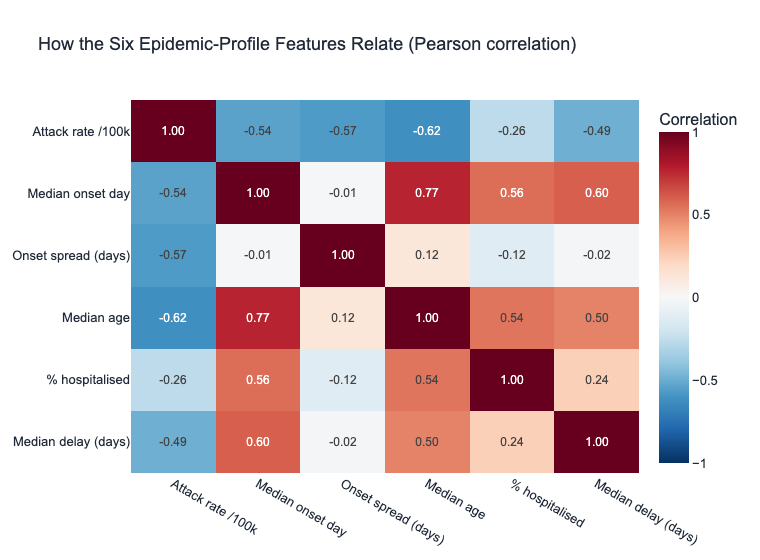

STRONGEST RELATIONSHIPS:


,feature_1,feature_2,correlation
0,Median onset day,Median age,0.77
1,Attack rate /100k,Median age,-0.62
2,Median onset day,Median delay (days),0.60
3,Attack rate /100k,Onset spread (days),-0.57
4,Median onset day,% hospitalised,0.56


In [3]:
# Lesson 18 — Step 3: Scale the features and check how they relate
import plotly.io as pio
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler

# House style for every chart in this lesson
pio.renderers.default = "plotly_mimetype+png"   # interactive in VS Code + PNG copy for GitHub
HOUSE = dict(
    template="plotly_white",
    font=dict(family="Arial", size=13, color="#1F2937"),
    hoverlabel=dict(bgcolor="white", bordercolor="#9CA3AF", font=dict(size=12, color="#111827")),
)
labels = {"attack_rate": "Attack rate /100k", "median_onset_day": "Median onset day",
          "onset_spread_days": "Onset spread (days)", "median_age": "Median age",
          "pct_hospitalised": "% hospitalised", "median_delay_days": "Median delay (days)"}

# --- Why scaling: features live on very different scales ---
print("STANDARD DEVIATION OF EACH FEATURE (before scaling):")
display(features[feature_cols].std().round(1).rename(labels).to_frame("SD"))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features[feature_cols])
print(f"After scaling: every feature has mean {X_scaled.mean(axis=0).mean():.1f} "
      f"and standard deviation {X_scaled.std(axis=0).mean():.1f}")

# --- Correlation between features (interactive heatmap with values) ---
corr = features[feature_cols].corr().round(2)
names = [labels[c] for c in feature_cols]
fig = go.Figure(go.Heatmap(
    z=corr.values, x=names, y=names, zmin=-1, zmax=1, colorscale="RdBu_r",
    text=corr.values, texttemplate="%{text:.2f}", textfont=dict(size=12),
    colorbar=dict(title="Correlation"),
    hovertemplate="<b>%{y}</b> vs <b>%{x}</b><br>Correlation: <b>%{z:.2f}</b><extra></extra>",
))
fig.update_layout(**HOUSE, title="How the Six Epidemic-Profile Features Relate (Pearson correlation)",
                  height=560, width=760)
fig.update_yaxes(autorange="reversed")
fig.show()

print("STRONGEST RELATIONSHIPS:")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename_axis(["feature_1", "feature_2"]).reset_index(name="correlation"))
pairs["strength"] = pairs["correlation"].abs()
display(pairs.sort_values("strength", ascending=False).head(5)
        .replace(labels).drop(columns="strength").reset_index(drop=True))

## Step 4 — K-means: Choosing the Number of Clusters

K-means was run for k = 2 to 8 (20 random starts each). The elbow method looks for the point where adding clusters stops reducing within-cluster spread (inertia) substantially; the silhouette score measures how clearly each area belongs to its own cluster. When the two disagree, the choice is made by comparing what the candidate solutions actually describe.

CHOOSING k — elbow (inertia), silhouette and cluster sizes:


,k,inertia,silhouette,smallest_cluster,inertia_drop_pct
0,2,216.989,0.345,22,NaN
1,3,144.114,0.428,10,33.6
2,4,108.937,0.380,9,24.4
3,5,87.193,0.383,1,20.0
4,6,80.179,0.317,1,8.0
5,7,65.451,0.347,1,18.4
6,8,59.339,0.274,1,9.3


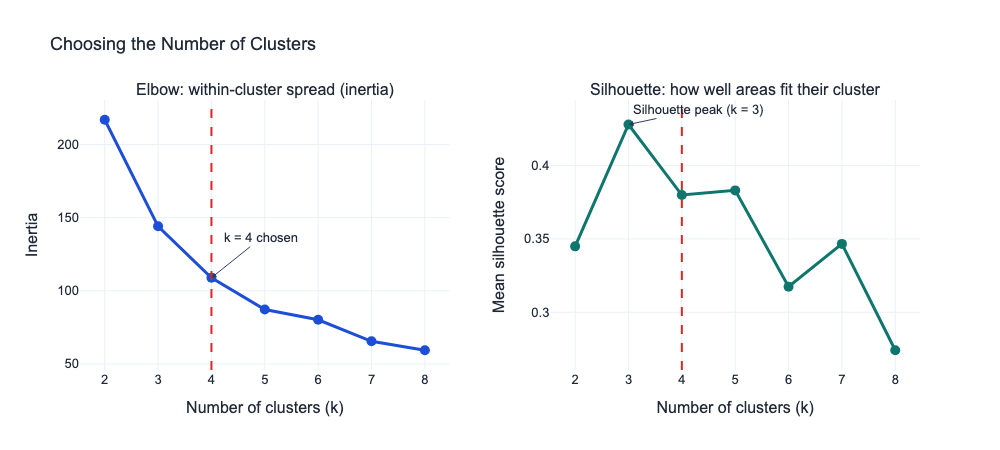


CLUSTER MEDIANS WITH k = 3 (sorted by timing):


,Attack rate /100k,Median onset day,Onset spread (days),Median age,% hospitalised,Median delay (days),areas
cluster,,,,,,,
2,276.9,62.0,40.1,28.0,16.5,2.0,27
0,51.1,83.0,133.4,32.0,17.5,3.0,10
1,144.2,109.0,36.0,36.0,22.4,3.0,23



CLUSTER MEDIANS WITH k = 4 (sorted by timing):


,Attack rate /100k,Median onset day,Onset spread (days),Median age,% hospitalised,Median delay (days),areas
cluster,,,,,,,
1,350.1,53.0,29.8,27.0,14.2,2.0,15
2,53.7,79.0,135.4,32.0,18.4,3.0,9
3,200.3,85.0,47.0,30.0,17.6,3.0,18
0,137.8,111.5,32.3,37.0,22.6,4.0,18


In [4]:
# Lesson 18 — Step 4: K-means — how many clusters?
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_scaled)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X_scaled, km.labels_),
                 "smallest_cluster": int(np.bincount(km.labels_).min())})
k_table = pd.DataFrame(rows)
k_table["inertia_drop_pct"] = (-k_table["inertia"].pct_change() * 100).round(1)
print("CHOOSING k — elbow (inertia), silhouette and cluster sizes:")
display(k_table.round(3))

# --- Interactive chart: elbow and silhouette side by side ---
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12,
                    subplot_titles=("Elbow: within-cluster spread (inertia)",
                                    "Silhouette: how well areas fit their cluster"))
fig.add_trace(go.Scatter(x=k_table["k"], y=k_table["inertia"], mode="lines+markers",
                         line=dict(color="#1D4ED8", width=3), marker=dict(size=10),
                         customdata=k_table[["inertia_drop_pct", "smallest_cluster"]],
                         hovertemplate=("<b>k = %{x}</b><br>Inertia: %{y:.1f}<br>Drop vs k−1: %{customdata[0]}%"
                                        "<br>Smallest cluster: %{customdata[1]} areas<extra></extra>"),
                         showlegend=False), row=1, col=1)
fig.add_trace(go.Scatter(x=k_table["k"], y=k_table["silhouette"], mode="lines+markers",
                         line=dict(color="#0F766E", width=3), marker=dict(size=10),
                         customdata=k_table[["smallest_cluster"]],
                         hovertemplate=("<b>k = %{x}</b><br>Silhouette: %{y:.3f}"
                                        "<br>Smallest cluster: %{customdata[0]} areas<extra></extra>"),
                         showlegend=False), row=1, col=2)
for col in (1, 2):
    fig.add_vline(x=4, line_dash="dash", line_color="#DC2626", row=1, col=col)
fig.add_annotation(x=4, y=k_table.loc[k_table["k"] == 4, "inertia"].iloc[0], text="k = 4 chosen",
                   showarrow=True, arrowhead=2, ax=50, ay=-40, row=1, col=1)
fig.add_annotation(x=3, y=k_table["silhouette"].max(), text="Silhouette peak (k = 3)",
                   showarrow=True, arrowhead=2, ax=70, ay=-15, row=1, col=2)
fig.update_xaxes(title_text="Number of clusters (k)", dtick=1)
fig.update_yaxes(title_text="Inertia", row=1, col=1)
fig.update_yaxes(title_text="Mean silhouette score", row=1, col=2)
fig.update_layout(**HOUSE, title="Choosing the Number of Clusters", height=450, width=1000)
fig.show()

# --- What changes between k = 3 and k = 4? Cluster medians in real units ---
for k in (3, 4):
    labels_k = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X_scaled)
    profile = (features.assign(cluster=labels_k).groupby("cluster")[feature_cols].median()
               .round(1).assign(areas=np.bincount(labels_k)).sort_values("median_onset_day"))
    print(f"\nCLUSTER MEDIANS WITH k = {k} (sorted by timing):")
    display(profile.rename(columns=labels))

## Step 5 — Final K-means Solution (k = 4) and Cluster Profiles

k = 4 was chosen: the silhouette score peaks at k = 3, but k = 3 merges early high-intensity outbreaks with later, longer, lower-intensity waves — operationally different situations. k = 5 or more creates single-area clusters. Clusters are named from their feature profiles using fixed rules (widest onset spread, earliest, latest, remaining), not from the hidden answer key.

CLUSTER PROFILES (medians across member areas):


,Attack rate /100k,Median onset day,Onset spread (days),Median age,% hospitalised,Median delay (days),areas,total_cases
cluster,,,,,,,,
"Early, intense surge",350.1,53.0,29.8,27.0,14.2,2.0,15,4332
Mid-season sustained wave,200.3,85.0,47.0,30.0,17.6,3.0,18,2658
"Late wave, older and more severe",137.8,111.5,32.3,37.0,22.6,4.0,18,1890
"Sporadic, prolonged low-level",53.7,79.0,135.4,32.0,18.4,3.0,9,382


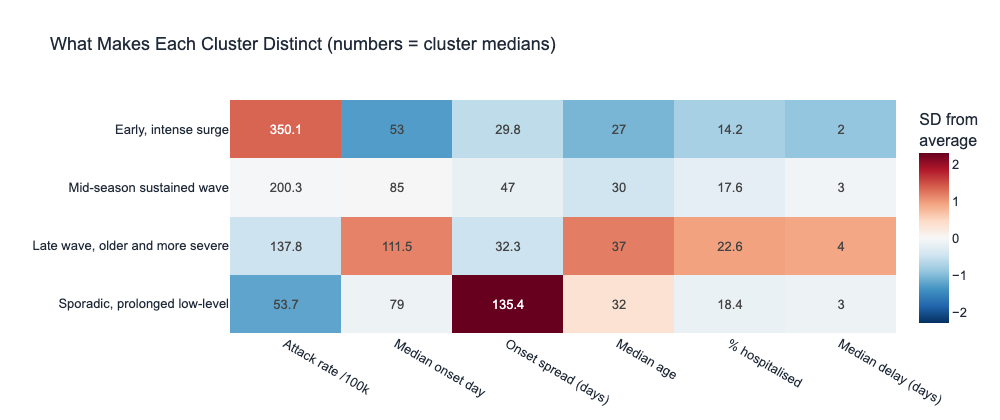


MEMBER AREAS BY CLUSTER:
  Early, intense surge (15): HA-06, HA-07, HA-15, HA-17, HA-19, HA-20, HA-35, HA-36, HA-41, HA-43, HA-50, HA-51, HA-54, HA-55, HA-57
  Mid-season sustained wave (18): HA-05, HA-09, HA-10, HA-14, HA-16, HA-18, HA-22, HA-23, HA-24, HA-31, HA-32, HA-33, HA-38, HA-40, HA-42, HA-44, HA-49, HA-53
  Late wave, older and more severe (18): HA-01, HA-03, HA-04, HA-08, HA-12, HA-13, HA-25, HA-27, HA-28, HA-29, HA-37, HA-45, HA-47, HA-48, HA-56, HA-58, HA-59, HA-60
  Sporadic, prolonged low-level (9): HA-02, HA-11, HA-21, HA-26, HA-30, HA-34, HA-39, HA-46, HA-52


In [5]:
# Lesson 18 — Step 5: Final K-means (k = 4) and cluster profiles
k_final = 4
kmeans = KMeans(n_clusters=k_final, n_init=20, random_state=42).fit(X_scaled)
features["cluster_id"] = kmeans.labels_

# --- Name clusters from their profiles (rules based on the features, not the answer key) ---
med = features.groupby("cluster_id")[feature_cols].median()
names = {}
sporadic = med["onset_spread_days"].idxmax()                       # widest spread of onsets
names[sporadic] = "Sporadic, prolonged low-level"
rest = med.drop(index=sporadic)
names[rest["median_onset_day"].idxmin()] = "Early, intense surge"   # earliest of the waves
names[rest["median_onset_day"].idxmax()] = "Late wave, older and more severe"
names[[c for c in rest.index if c not in names][0]] = "Mid-season sustained wave"
features["cluster"] = features["cluster_id"].map(names)

cluster_order = ["Early, intense surge", "Mid-season sustained wave",
                 "Late wave, older and more severe", "Sporadic, prolonged low-level"]
CLUSTER_COLORS = dict(zip(cluster_order, ["#DC2626", "#F59E0B", "#7C3AED", "#6B7280"]))

profile = (features.groupby("cluster")[feature_cols].median().round(1)
           .assign(areas=features.groupby("cluster").size(),
                   total_cases=features.groupby("cluster")["cases"].sum())
           .loc[cluster_order])
print("CLUSTER PROFILES (medians across member areas):")
display(profile.rename(columns=labels))

# --- Interactive profile heatmap: colour = how far above/below the regional average (SD units) ---
z = pd.DataFrame(X_scaled, columns=feature_cols).assign(cluster=features["cluster"])
z_mean = z.groupby("cluster")[feature_cols].mean().loc[cluster_order]
fig = go.Figure(go.Heatmap(
    z=z_mean.values, x=[labels[c] for c in feature_cols], y=cluster_order,
    zmid=0, colorscale="RdBu_r", colorbar=dict(title="SD from<br>average"),
    text=profile[feature_cols].values, texttemplate="%{text}", textfont=dict(size=13),
    hovertemplate=("<b>%{y}</b><br>%{x}: <b>%{text}</b> (cluster median)"
                   "<br>%{z:+.2f} SD from the regional average<extra></extra>"),
))
fig.update_layout(**HOUSE, title="What Makes Each Cluster Distinct (numbers = cluster medians)",
                  height=420, width=1000, margin=dict(l=230))
fig.update_yaxes(autorange="reversed")
fig.show()
fig_profile = fig
print("\nMEMBER AREAS BY CLUSTER:")
for name in cluster_order:
    members = features.loc[features["cluster"] == name, "area"].tolist()
    print(f"  {name} ({len(members)}): {', '.join(members)}")

## Step 6 — Hierarchical Clustering (Ward Linkage) and Comparison with K-means

Ward's method merges, at each step, the two groups whose union adds the least within-group spread, building a tree (dendrogram) of all 60 areas. Cutting the tree into four branches gives a second, independent clustering. Agreement with K-means is measured with the Adjusted Rand Index.

Agreement between K-means and hierarchical clusters (Adjusted Rand Index): 0.948
(1 = identical groupings, 0 = no better than random)

K-MEANS (rows) vs HIERARCHICAL (columns):


hier_cluster,"Early, intense surge",Mid-season sustained wave,"Late wave, older and more severe","Sporadic, prolonged low-level"
cluster,,,,
"Early, intense surge",15,0,0,0
Mid-season sustained wave,0,17,1,0
"Late wave, older and more severe",0,0,18,0
"Sporadic, prolonged low-level",0,0,0,9



AREAS PLACED DIFFERENTLY BY THE TWO METHODS: 1


,area,cases,cluster,hier_cluster,Attack rate /100k,Median onset day,Onset spread (days),Median age,% hospitalised,Median delay (days)
17,HA-18,207,Mid-season sustained wave,"Late wave, older and more severe",292.8,99.0,38.8,30.0,26.1,3.0


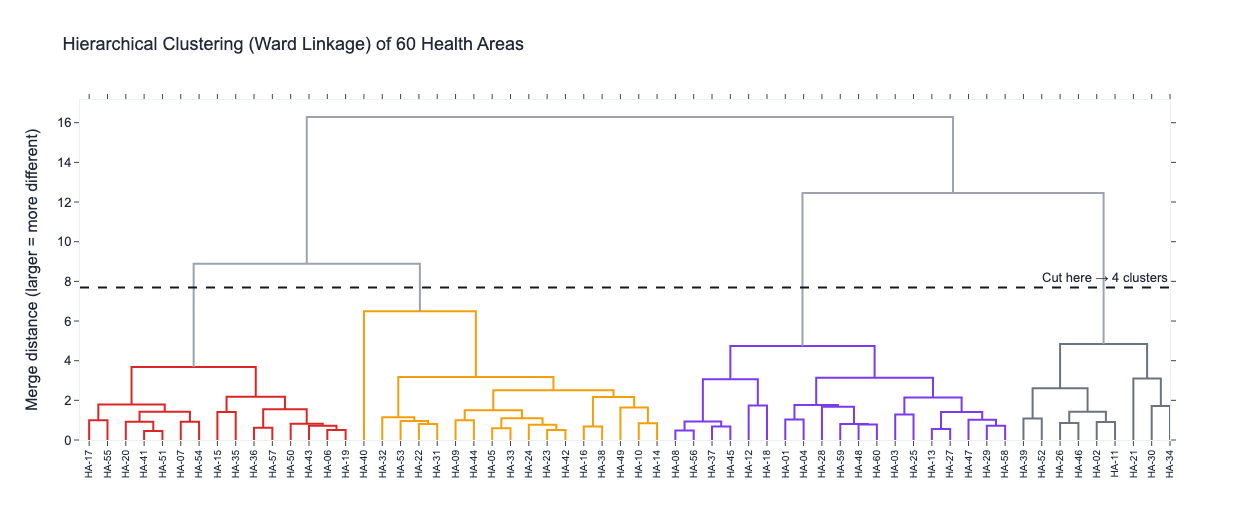

In [6]:
# Lesson 18 — Step 6: Hierarchical clustering (Ward) and comparison with K-means
import plotly.figure_factory as ff
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score

# --- Build the merge tree: Ward linkage joins the two groups that add the least spread ---
Z = linkage(X_scaled, method="ward")
cut_height = (Z[-4, 2] + Z[-3, 2]) / 2            # a height that leaves exactly 4 branches
features["hier_id"] = fcluster(Z, t=4, criterion="maxclust")

# Name each hierarchical cluster after the K-means cluster most of its areas belong to
majority = features.groupby("hier_id")["cluster"].agg(lambda s: s.mode()[0])
features["hier_cluster"] = features["hier_id"].map(majority)

# --- Do the two methods agree? ---
agreement = adjusted_rand_score(features["cluster"], features["hier_id"])
print(f"Agreement between K-means and hierarchical clusters (Adjusted Rand Index): {agreement:.3f}")
print("(1 = identical groupings, 0 = no better than random)\n")

xtab = pd.crosstab(features["cluster"], features["hier_cluster"]).reindex(
    index=cluster_order, columns=cluster_order, fill_value=0)
print("K-MEANS (rows) vs HIERARCHICAL (columns):")
display(xtab)

diff = features.loc[features["hier_cluster"] != features["cluster"],
                    ["area", "cases", "cluster", "hier_cluster"] + feature_cols]
print(f"\nAREAS PLACED DIFFERENTLY BY THE TWO METHODS: {len(diff)}")
display(diff.rename(columns=labels))

# --- Interactive dendrogram, coloured with the same cluster colours as the rest of the lesson ---
fig = ff.create_dendrogram(X_scaled, labels=features["area"].tolist(),
                           linkagefun=lambda x: linkage(x, method="ward"))
leaf_x = dict(zip(fig.layout.xaxis.tickvals, fig.layout.xaxis.ticktext))
area_cluster = dict(zip(features["area"], features["hier_cluster"]))
for trace in fig.data:
    xs, ys = np.array(trace.x), np.array(trace.y)
    if ys.max() > cut_height:                                   # merges above the cut
        colour, name = "#9CA3AF", "Merged above the cut"
    else:                                                       # inside one cluster
        nearest = min(leaf_x, key=lambda v: abs(v - xs.mean()))
        name = area_cluster[leaf_x[nearest]]
        colour = CLUSTER_COLORS[name]
    trace.update(line=dict(color=colour, width=2), hovertemplate=f"{name}<extra></extra>")
fig.add_hline(y=cut_height, line_dash="dash", line_color="#111827",
              annotation_text="Cut here → 4 clusters", annotation_position="top right")
fig.update_layout(**HOUSE, title="Hierarchical Clustering (Ward Linkage) of 60 Health Areas",
                  height=520, width=1250, showlegend=False,
                  yaxis_title="Merge distance (larger = more different)")
fig.update_xaxes(tickangle=-90, tickfont=dict(size=10))
fig.show()

## Step 7 — PCA View and Cluster Map

Principal component analysis (PCA) compresses the six standardised features into two axes that capture as much variation as possible, so that cluster separation can be inspected visually. The loadings show which features drive each axis. The cluster map places each area at its location in the region, to test whether epidemic profiles form geographic zones — a pattern the clustering was never told about.

PC1 explains 52.0% and PC2 23.0% of the variation (together 75.0%).

WHAT EACH AXIS MEANS (loadings: how strongly each feature drives the axis):


,PC1,PC2
Attack rate /100k,-0.44,-0.44
Median onset day,0.50,-0.20
Onset spread (days),0.12,0.78
Median age,0.50,-0.06
% hospitalised,0.35,-0.37
Median delay (days),0.40,-0.09



GEOGRAPHY OF EACH CLUSTER (km from the regional town centre):


,min,median,max
cluster,,,
"Early, intense surge",0.0,9.7,21.4
Mid-season sustained wave,15.2,23.4,34.1
"Late wave, older and more severe",32.6,40.1,47.9
"Sporadic, prolonged low-level",16.9,27.0,40.5


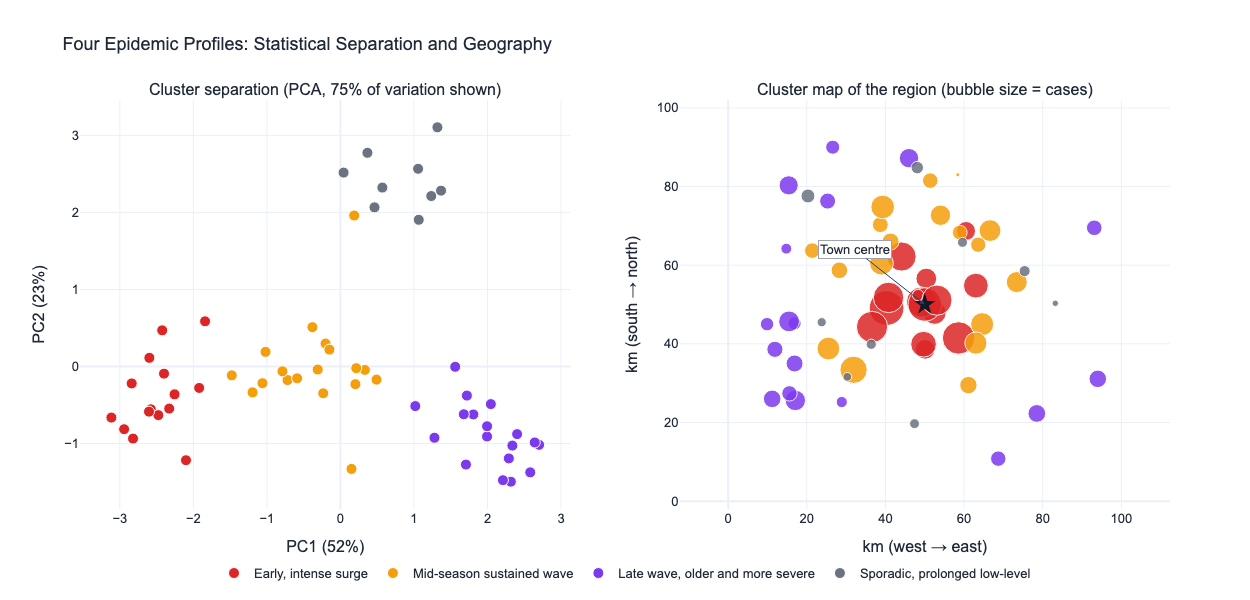

In [7]:
# Lesson 18 — Step 7: PCA view and a cluster map of the region
from sklearn.decomposition import PCA

# --- PCA: compress six features into two axes for plotting ---
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_scaled)
features["PC1"], features["PC2"] = pcs[:, 0], pcs[:, 1]
var = pca.explained_variance_ratio_ * 100
print(f"PC1 explains {var[0]:.1f}% and PC2 {var[1]:.1f}% of the variation (together {var.sum():.1f}%).")

loadings = pd.DataFrame(pca.components_.T, index=[labels[c] for c in feature_cols],
                        columns=["PC1", "PC2"]).round(2)
print("\nWHAT EACH AXIS MEANS (loadings: how strongly each feature drives the axis):")
display(loadings)

# --- Distance from the regional town centre (50, 50 km) ---
features["km_from_centre"] = np.hypot(features["x_km"] - 50, features["y_km"] - 50).round(1)
print("\nGEOGRAPHY OF EACH CLUSTER (km from the regional town centre):")
display(features.groupby("cluster")["km_from_centre"].describe()[["min", "50%", "max"]]
        .round(1).loc[cluster_order].rename(columns={"50%": "median"}))

# --- Interactive figure: PCA scatter and cluster map side by side ---
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.10,
                    subplot_titles=(f"Cluster separation (PCA, {var.sum():.0f}% of variation shown)",
                                    "Cluster map of the region (bubble size = cases)"))
hover = ("<b>%{customdata[0]}</b> — %{customdata[1]}<br>Cases: %{customdata[2]}"
         "<br>Attack rate: %{customdata[3]:.0f} per 100k<br>Median onset day: %{customdata[4]:.0f}"
         "<br>Median age: %{customdata[5]:.0f}<br>Hospitalised: %{customdata[6]:.1f}%<extra></extra>")
cols = ["area", "cluster", "cases", "attack_rate", "median_onset_day", "median_age", "pct_hospitalised"]
for name in cluster_order:
    d = features[features["cluster"] == name]
    fig.add_trace(go.Scatter(x=d["PC1"], y=d["PC2"], mode="markers", name=name, legendgroup=name,
                             marker=dict(color=CLUSTER_COLORS[name], size=11, line=dict(color="white", width=1)),
                             customdata=d[cols], hovertemplate=hover), row=1, col=1)
    fig.add_trace(go.Scatter(x=d["x_km"], y=d["y_km"], mode="markers", name=name, legendgroup=name,
                             showlegend=False,
                             marker=dict(color=CLUSTER_COLORS[name], size=np.sqrt(d["cases"]) * 1.6,
                                         opacity=0.85, line=dict(color="white", width=1)),
                             customdata=d[cols], hovertemplate=hover), row=1, col=2)
fig.add_trace(go.Scatter(x=[50], y=[50], mode="markers", showlegend=False, hoverinfo="skip",
                         marker=dict(symbol="star", size=16, color="#111827")), row=1, col=2)
fig.add_annotation(x=50, y=50, text="Town centre", showarrow=True, arrowhead=2, ax=-70, ay=-55,
                   bgcolor="white", bordercolor="#9CA3AF", row=1, col=2)
fig.update_xaxes(title_text=f"PC1 ({var[0]:.0f}%)", row=1, col=1)
fig.update_yaxes(title_text=f"PC2 ({var[1]:.0f}%)", row=1, col=1)
fig.update_xaxes(title_text="km (west → east)", range=[-2, 102], row=1, col=2)
fig.update_yaxes(title_text="km (south → north)", range=[-2, 102], scaleanchor="x2", row=1, col=2)
fig.update_layout(**HOUSE, title="Four Epidemic Profiles: Statistical Separation and Geography",
                  height=600, width=1250,
                  legend=dict(orientation="h", yanchor="top", y=-0.12, xanchor="center", x=0.5))
fig.show()
fig_map = fig

## Step 8 — Validation: Truth, Stability and Per-Area Confidence

The hidden answer key is opened only now, after all clustering decisions were made. Agreement is measured with the Adjusted Rand Index. Stability is tested by re-clustering 200 bootstrap resamples of the 60 areas. Per-area silhouette scores identify areas that sit between clusters.

Agreement with the hidden patterns (Adjusted Rand Index): 0.914

HIDDEN PATTERN (rows) vs DISCOVERED CLUSTER (columns):


cluster,"Early, intense surge",Mid-season sustained wave,"Late wave, older and more severe","Sporadic, prolonged low-level"
true_pattern,,,,
Early urban surge,14,0,0,0
Sustained peri-urban,1,17,0,0
Late rural wave,0,0,18,0
Sporadic low-level,0,1,0,9



Bootstrap stability (200 resamples): median ARI 0.954, 5th percentile 0.534

LOWEST-CONFIDENCE AREAS (smallest silhouette):


,area,cases,cluster,true_pattern,silhouette,matches_truth
30,HA-31,291,Mid-season sustained wave,Sustained peri-urban,-0.028,True
37,HA-38,173,Mid-season sustained wave,Sustained peri-urban,0.034,True
39,HA-40,6,Mid-season sustained wave,Sporadic low-level,0.036,False
21,HA-22,91,Mid-season sustained wave,Sustained peri-urban,0.041,True
17,HA-18,207,Mid-season sustained wave,Sustained peri-urban,0.105,True
31,HA-32,202,Mid-season sustained wave,Sustained peri-urban,0.131,True


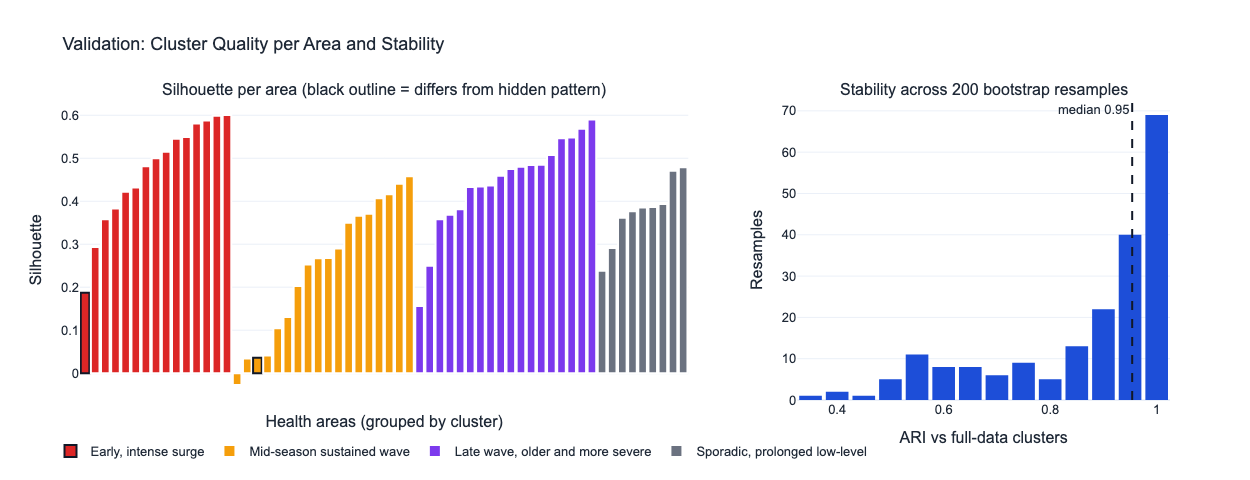

In [8]:
# Lesson 18 — Step 8: Validation — are the clusters real and stable?
from sklearn.metrics import silhouette_samples

# --- 8a. Open the sealed answer key (first time it is used) ---
truth = q(f"SELECT area_id, true_pattern FROM read_parquet('{data_dir / 'answer_key.parquet'}')")
features = features.drop(columns="true_pattern", errors="ignore").merge(truth, on="area_id")

ari_truth = adjusted_rand_score(features["true_pattern"], features["cluster"])
print(f"Agreement with the hidden patterns (Adjusted Rand Index): {ari_truth:.3f}")
truth_order = ["Early urban surge", "Sustained peri-urban", "Late rural wave", "Sporadic low-level"]
print("\nHIDDEN PATTERN (rows) vs DISCOVERED CLUSTER (columns):")
display(pd.crosstab(features["true_pattern"], features["cluster"])
        .reindex(index=truth_order, columns=cluster_order, fill_value=0))

# --- 8b. Stability: re-cluster 200 bootstrap samples of areas ---
rng_boot = np.random.default_rng(42)
boot_ari = []
for _ in range(200):
    idx = rng_boot.choice(len(features), size=len(features), replace=True)
    km_b = KMeans(n_clusters=k_final, n_init=10, random_state=0).fit(X_scaled[idx])
    boot_ari.append(adjusted_rand_score(features["cluster_id"].values[idx], km_b.labels_))
boot_ari = np.array(boot_ari)
print(f"\nBootstrap stability (200 resamples): median ARI {np.median(boot_ari):.3f}, "
      f"5th percentile {np.percentile(boot_ari, 5):.3f}")

# --- 8c. Which individual areas are uncertain? (silhouette per area) ---
features["silhouette"] = silhouette_samples(X_scaled, features["cluster_id"])
features["matches_truth"] = [
    {"Early urban surge": "Early, intense surge", "Sustained peri-urban": "Mid-season sustained wave",
     "Late rural wave": "Late wave, older and more severe",
     "Sporadic low-level": "Sporadic, prolonged low-level"}[t] == c
    for t, c in zip(features["true_pattern"], features["cluster"])]
print("\nLOWEST-CONFIDENCE AREAS (smallest silhouette):")
display(features.nsmallest(6, "silhouette")[["area", "cases", "cluster", "true_pattern",
                                             "silhouette", "matches_truth"]].round(3))

# --- Figure: silhouette plot and bootstrap stability ---
sil = features.sort_values(["cluster", "silhouette"], key=lambda s: s.map(
    {n: i for i, n in enumerate(cluster_order)}) if s.name == "cluster" else s)
fig = make_subplots(rows=1, cols=2, column_widths=[0.62, 0.38], horizontal_spacing=0.10,
                    subplot_titles=("Silhouette per area (black outline = differs from hidden pattern)",
                                    "Stability across 200 bootstrap resamples"))
for name in cluster_order:
    d = sil[sil["cluster"] == name]
    fig.add_trace(go.Bar(x=d["area"], y=d["silhouette"], name=name,
                         marker_color=CLUSTER_COLORS[name],
                         marker_line=dict(color=np.where(d["matches_truth"], "white", "#111827"), width=2),
                         customdata=d[["cluster", "true_pattern", "cases"]],
                         hovertemplate=("<b>%{x}</b><br>Cluster: %{customdata[0]}<br>Hidden pattern: "
                                        "%{customdata[1]}<br>Cases: %{customdata[2]}"
                                        "<br>Silhouette: <b>%{y:.2f}</b><extra></extra>")), row=1, col=1)
fig.add_trace(go.Histogram(x=boot_ari, nbinsx=20, marker_color="#1D4ED8", showlegend=False,
                           hovertemplate="ARI %{x}<br>%{y} resamples<extra></extra>"), row=1, col=2)
fig.add_vline(x=np.median(boot_ari), line_dash="dash", line_color="#111827", row=1, col=2,
              annotation_text=f"median {np.median(boot_ari):.2f}", annotation_position="top left")
fig.update_xaxes(showticklabels=False, title_text="Health areas (grouped by cluster)", row=1, col=1)
fig.update_yaxes(title_text="Silhouette", row=1, col=1)
fig.update_xaxes(title_text="ARI vs full-data clusters", row=1, col=2)
fig.update_yaxes(title_text="Resamples", row=1, col=2)
fig.update_layout(**HOUSE, title="Validation: Cluster Quality per Area and Stability",
                  height=480, width=1250, bargap=0.15,
                  legend=dict(orientation="h", yanchor="top", y=-0.12, xanchor="center", x=0.35))
fig.show()

## Step 9 — Publication Figures

In [9]:
# Lesson 18 — Step 9: Save publication figures and the interactive map
fig_dir = repo_root / "figures"
docs_dir = repo_root / "docs"
docs_dir.mkdir(exist_ok=True)

fig_profile.write_image(fig_dir / "lesson18_cluster_profiles.png", width=1100, height=440, scale=2)
fig_map.write_image(fig_dir / "lesson18_cluster_map.png", width=1250, height=600, scale=2)

# Interactive map for GitHub Pages (automatic width so it fills the browser)
map_page = go.Figure(fig_map)
map_page.update_layout(width=None)
map_page.write_html(docs_dir / "health_area_clusters.html", include_plotlyjs="cdn",
                    config={"displaylogo": False, "responsive": True})

print("Saved:", sorted(p.name for p in fig_dir.glob("lesson18_*.png")),
      "and docs/health_area_clusters.html")

Saved: ['lesson18_cluster_map.png', 'lesson18_cluster_profiles.png'] and docs/health_area_clusters.html


## Conclusions

1. **Four distinct epidemic profiles.** K-means (k = 4) on six standardised features grouped 60 health areas into: an *early, intense surge* (15 areas; median attack rate 350 per 100,000, median onset day 53, youngest patients); a *mid-season sustained wave* (18; attack rate 200, day 85); a *late wave, older and more severe* (18; attack rate 138, day 112, median age 37, 22.6% hospitalised, slowest reporting); and *sporadic, prolonged low-level* transmission (9; attack rate 54, onsets spread over 135 days).
2. **Choosing k required judgement.** The silhouette score peaked at k = 3 (0.428 vs 0.380 at k = 4), but k = 3 merged early high-intensity outbreaks with later, longer, lower-intensity waves — situations needing different responses. k ≥ 5 produced single-area clusters.
3. **Two independent methods agreed.** Ward hierarchical clustering matched K-means for 59 of 60 areas (ARI 0.948); the one disagreement (HA-18) combines late timing and high hospitalisation with a high attack rate and young patients — a genuine borderline case.
4. **The clusters recovered the hidden patterns** (ARI 0.914; 58 of 60 areas). The two misplacements were a 6-case area with an unreliable profile and an area on the soft urban/peri-urban boundary. Clusters were stable under 200 bootstrap resamples (median ARI 0.954; 5th percentile 0.534).
5. **The profiles form geographic rings.** Without using coordinates, the clusters arranged themselves around the town centre: early surges at a median 10 km, mid-season waves at 23 km and late, more severe waves at 40 km, with sporadic areas scattered — consistent with spread outward from an urban hub.

**Limitations:** synthetic data with known structure; 60 areas limit stability; areas with few cases have noisy profiles; clusters describe past outbreaks and should be reviewed with field teams before guiding resource allocation.